# GVH Diagonal Cubic — Hierarchical Cube & Frequency Minimal Benchmark

**Notebook complémentaire** aux audits `.3.3.27.3` (paramètres prescrits/dérivés) et `.3.3.27.4` (pont dimensionnel SI). Il **ne remplace pas** les notebooks canoniques.

## Questions testables

1. À quelle distance deux sous-cubes Terre et Lune peuvent-ils être remplacés par un cube effectif au barycentre, avec une erreur de gravité extérieure contrôlée ?
2. Quelle fréquence orbitale la physique newtonienne prédit-elle pour la Lune avec des constantes externes, et quel est l'écart à la période réelle ?
3. Que signifie comparer cette fréquence à une fréquence atomique de référence sur une **seule** base SI ?

## Architecture scientifique obligatoire

1. Niveau 1 — GVH : **hypothèse de hiérarchie des cubes**, sans nouvelle équation dynamique dérivée.
2. Niveau 2 — Physique établie : gravitation newtonienne, barycentre, fréquence orbitale et fréquence du césium.
3. Niveau 3 — Test numérique minimal : erreurs de monopole et rapports de fréquence, sans ajustement des paramètres.
4. Niveau 4 — Verdict scientifique : cohérence du **benchmark**, pas validation d'une nouvelle physique GVH.

## Non-circularité / provenance

Checkpoint amont `.3.3.27.3` exécuté : SHA-256 `575f3dbfac2e7fec9bfada6054e2040e59692122ef43cdf408e6a7318ce70d1e`.

Les entrées physiques de ce test sont externes, déjà mesurées ; aucune échelle `L_*` ou `T_*` GVH n'est dérivée ni ajustée ici. Les nombres terrestres/lunaires servent de **conditions de benchmark de physique établie**. Ils ne deviennent jamais des prédictions GVH.

**Sources** :
- NASA/JPL (GM Terre, Lune et paramètres astronomiques) : https://ssd.jpl.nasa.gov/astro_par.html
- NASA (semi-grand axe et période sidérale de la Lune) : https://nssdc.gsfc.nasa.gov/planetary/factsheet/moonfact.html
- NASA (période sidérale de la Terre) : https://nssdc.gsfc.nasa.gov/planetary/factsheet/earthfact.html
- NIST (définition de la seconde par le césium 133) : https://www.nist.gov/pml/owm/si-units-time


# Niveau 1 — GVH : cubes internes et cube effectif

## Construction opérationnelle, pas nouvelle loi

Dans le cadre proposé, Terre et Lune sont des sous-cubes. À une résolution plus grossière, ils deviennent un cube effectif, caractérisé ici par un barycentre et la somme des paramètres gravitationnels :

\[
\boldsymbol x_{\rm CM}=\frac{\mu_E\boldsymbol x_E+\mu_M\boldsymbol x_M}{\mu_E+\mu_M},
\qquad \mu_{\rm eff}=\mu_E+\mu_M.
\]

Cette opération est **déjà établie en mécanique newtonienne**. Le test évalue seulement si elle peut constituer un témoin minimal d'agrégation pour l'architecture GVH.

Dans un référentiel barycentrique et un modèle circulaire d'écartement fixe `d`, les deux positions sont

\[
\boldsymbol x_E=-d\frac{\mu_M}{\mu_E+\mu_M}\hat{\boldsymbol n}(\theta),
\quad
\boldsymbol x_M=+d\frac{\mu_E}{\mu_E+\mu_M}\hat{\boldsymbol n}(\theta).
\]

Aucune EOM GVH n'impose ici ces mouvements : l'angle est **prescrit pour le balayage numérique**.


In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd

# Références : JPL DE440 en km^3/s^2, converties en m^3/s^2.
MU_EARTH = 398600.435507 * 1e9
MU_MOON = 4902.800118 * 1e9
MU_TOTAL = MU_EARTH + MU_MOON
D_EARTH_MOON = 384_400_000.0  # m, NASA: demi-grand axe de référence (pas orbite circulaire exacte)
P_MOON_OBS_D = 27.3217  # d, NASA: période de révolution sidérale
P_EARTH_OBS_D = 365.256  # d, NASA: période de révolution sidérale autour du Soleil
F_CS = 9_192_631_770.0  # Hz, NIST: définition de la seconde SI
DAY_S = 86400.0

# Tolérance de modélisation illustrative FIXÉE avant le calcul : 0.01 %.
# Ce n'est PAS un seuil dérivé de GVH.
REL_TOL_PERCENT = 0.01
PHASE_COUNT = 721
DISTANCES_M = np.array([1e9, 1e10, 1e11])

print('MU_EARTH [m^3/s^2] =', MU_EARTH)
print('MU_MOON [m^3/s^2] =', MU_MOON)
print('D_EARTH_MOON [m] =', D_EARTH_MOON)
print('Tolérance relative, pour illustration =', REL_TOL_PERCENT, '%')


MU_EARTH [m^3/s^2] = 398600435507000.0
MU_MOON [m^3/s^2] = 4902800118000.0
D_EARTH_MOON [m] = 384400000.0
Tolérance relative, pour illustration = 0.01 %


In [2]:
theta = np.linspace(0.0, 2*np.pi, PHASE_COUNT, endpoint=False)
unit_orbit = np.stack([np.cos(theta), np.sin(theta), np.zeros_like(theta)], axis=-1)
xE = (-D_EARTH_MOON*MU_MOON/MU_TOTAL)*unit_orbit
xM = (+D_EARTH_MOON*MU_EARTH/MU_TOTAL)*unit_orbit

# Identité barycentrique exacte (numériquement à la précision machine)
bary_residual = MU_EARTH*xE + MU_MOON*xM
relative_bary_residual = np.linalg.norm(bary_residual, axis=1).max()/(MU_TOTAL*D_EARTH_MOON)
BARYCENTER_IDENTITY_PASS = bool(relative_bary_residual < 1e-15)

assert BARYCENTER_IDENTITY_PASS
print('BARYCENTER_IDENTITY_PASS =', BARYCENTER_IDENTITY_PASS)
print('Relative barycenter identity residual =', relative_bary_residual)


BARYCENTER_IDENTITY_PASS = True
Relative barycenter identity residual = 3.484207300285072e-18


# Niveau 2 — Physique établie

## Deux masses ou un monopole ?

En gravitation newtonienne, l'accélération réelle d'une masse test en position `r` est :

\[
\boldsymbol a_{\rm 2corps}(\boldsymbol r)
=\sum_{i=E,M}\mu_i \frac{\boldsymbol x_i-\boldsymbol r}
{|\boldsymbol r-\boldsymbol x_i|^3}.
\]

L'approximation du cube effectif (monopole au barycentre) est :

\[
\boldsymbol a_{\rm eff}(\boldsymbol r)
=-\frac{\mu_{\rm total}}{|\boldsymbol r|^3}\boldsymbol r.
\]

L'erreur relative normalisée est

\[
\epsilon(\boldsymbol r,\theta)=
\frac{|\boldsymbol a_{\rm 2corps}-\boldsymbol a_{\rm eff}|}{|\boldsymbol a_{\rm eff}|}.
\]

On teste des points extérieurs à toute trajectoire interne, à trois distances fixes ; on balaye toutes les phases orbitales `theta`. Ce n'est pas une intégration N-corps réelle de l'orbite lunaire et ne comporte ni Soleil, ni marées, ni moments multipolaires de chaque corps.

## Fréquences physiques

Pour le problème newtonien circulaire à deux corps :

\[
f_{EM}^{(N)}=\frac{1}{2\pi}\sqrt{\frac{\mu_E+\mu_M}{d^3}}.
\]

Pour comparer aux données sans réglage :

\[
f_{\rm Lune,obs}=1/(27.3217\times 86400),
\quad f_{\rm Cs}=9\,192\,631\,770\;\mathrm{Hz}.
\]

La valeur du césium est une **définition métrologique** et non une oscillation d'un électron autour d'un noyau. Le rapport fréquentiel ne démontre pas un couplage physique.


# Niveau 3 — Test numérique minimal

## 3.1 Erreur d'agrégation au-dessus de trois distances

Le point test est `r=(R,0,0)` et les positions Terre/Lune tournent sur un cercle par angle `theta` uniformément balayé. **Le maximum est pris sur 721 phases**, pas sur la seule configuration alignée. On ne recherche pas le meilleur paramètre ; on compare deux représentations physiques connues.


In [3]:
def field_errors_at_distance(R_m, xE, xM):
    p = np.broadcast_to(np.array([R_m,0.0,0.0]), xE.shape)
    re = xE-p
    rm = xM-p
    a_two = (MU_EARTH * re/np.linalg.norm(re,axis=1)[:,None]**3
             + MU_MOON * rm/np.linalg.norm(rm,axis=1)[:,None]**3)
    a_mono = np.broadcast_to(np.array([-MU_TOTAL/R_m**2,0.0,0.0]), xE.shape)
    return np.linalg.norm(a_two-a_mono,axis=1)/(MU_TOTAL/R_m**2)

rows=[]
for R in DISTANCES_M:
    errors=field_errors_at_distance(R, xE, xM)
    rows.append({
        'distance_km':R/1e3,
        'max_error_percent':100*np.max(errors),
        'rms_error_percent':100*np.sqrt(np.mean(errors**2)),
        'mean_error_percent':100*np.mean(errors),
        'below_illustrative_tolerance':bool(100*np.max(errors)<REL_TOL_PERCENT),
    })
field_df=pd.DataFrame(rows)
print(field_df.to_string(index=False, float_format=lambda x: f'{x:.10g}'))

FIELD_ERROR_FALLS_WITH_DISTANCE=bool(np.all(np.diff(field_df['max_error_percent'])<0))
TOL_PASS_AT_1E10 = bool(field_df.loc[1,'below_illustrative_tolerance'])
TOL_FAIL_AT_1E9 = not bool(field_df.loc[0,'below_illustrative_tolerance'])
assert FIELD_ERROR_FALLS_WITH_DISTANCE and TOL_PASS_AT_1E10 and TOL_FAIL_AT_1E9
print('FIELD_ERROR_FALLS_WITH_DISTANCE =', FIELD_ERROR_FALLS_WITH_DISTANCE)
print('EXAMPLE_TOLERANCE_CRITERION_PASS_AT_1E10 =', TOL_PASS_AT_1E10)


 distance_km  max_error_percent  rms_error_percent  mean_error_percent  below_illustrative_tolerance
     1000000        1.026743805       0.4485914822        0.3827063723                         False
    10000000     0.005600102652     0.003649984405      0.003483665446                          True
   100000000    5.347522636e-05    3.642965058e-05     3.480682489e-05                          True
FIELD_ERROR_FALLS_WITH_DISTANCE = True
EXAMPLE_TOLERANCE_CRITERION_PASS_AT_1E10 = True


## 3.2 Fréquence orbitale et écart au réel

Nous utilisons uniquement `MU_EARTH`, `MU_MOON` et `D_EARTH_MOON` fournis indépendamment ; nous ne réglons **pas** la période calculée sur le résultat observé. Le modèle est à deux corps et ne peut pas intégrer les perturbations solaires.


In [4]:
f_moon_newton = (1/(2*np.pi))*np.sqrt(MU_TOTAL/D_EARTH_MOON**3)
p_moon_newton_d = 1/f_moon_newton/DAY_S
f_moon_observed = 1/(P_MOON_OBS_D*DAY_S)
rel_period_gap = (p_moon_newton_d/P_MOON_OBS_D-1)*100

print(f'P Moon Newton 2-corps = {p_moon_newton_d:.9f} days')
print(f'P Moon observed NASA = {P_MOON_OBS_D:.7f} days')
print(f'Gap signed = {rel_period_gap:.6f}%')
print(f'f Moon Newton = {f_moon_newton:.12g} Hz')
print(f'f Moon observed = {f_moon_observed:.12g} Hz')

assert abs(p_moon_newton_d-27.2846058)<1e-4
assert 0.1<abs(rel_period_gap)<0.2


P Moon Newton 2-corps = 27.284605798 days
P Moon observed NASA = 27.3217000 days
Gap signed = -0.135768%
f Moon Newton = 4.24197958359e-07 Hz
f Moon observed = 4.23622032087e-07 Hz


## 3.3 Rapports de fréquence et invariance d'une même unité temporelle

On compare trois fréquences *avec une seule définition de la seconde SI*. Sous une transformation de temps commune `t′ = αt`, toutes les fréquences deviennent `f′ = f/α`, donc le rapport `f1/f2` reste identique. **Utiliser des α différents pour chaque système pourrait fabriquer l'égalité souhaitée et n'est pas autorisé ici.**


In [5]:
f_earth_observed = 1/(P_EARTH_OBS_D*DAY_S)
ratio_cs_moon = F_CS/f_moon_observed
ratio_cs_earth = F_CS/f_earth_observed
ratio_earth_moon = f_moon_observed/f_earth_observed

freq_df=pd.DataFrame([
  {'signal':'Lune, fréquence observée','f_Hz':f_moon_observed,'status':'MESURÉ (période NASA)'},
  {'signal':'Terre, révolution autour du Soleil','f_Hz':f_earth_observed,'status':'MESURÉ (période NASA)'},
  {'signal':'Césium 133, transition hyperfine','f_Hz':F_CS,'status':'DÉFINI (seconde SI NIST)'},
])
print(freq_df.to_string(index=False))
print(f'Cs / Moon_observed frequency = {ratio_cs_moon:.12g}')
print(f'Cs / Earth_orbital frequency = {ratio_cs_earth:.12g}')
print(f'Moon_observed / Earth_orbital frequency = {ratio_earth_moon:.12g}')

COMMON_TIME_RESCALING_INVARIANCE_PASS=True
for alpha in (1e-9,1.0,1e9):
    common_ratio=(F_CS/alpha)/(f_moon_observed/alpha)
    COMMON_TIME_RESCALING_INVARIANCE_PASS &= bool(np.isclose(common_ratio,ratio_cs_moon,rtol=1e-14,atol=0))
assert COMMON_TIME_RESCALING_INVARIANCE_PASS
print('COMMON_TIME_RESCALING_INVARIANCE_PASS =',COMMON_TIME_RESCALING_INVARIANCE_PASS)


                            signal         f_Hz                   status
          Lune, fréquence observée 4.236220e-07    MESURÉ (période NASA)
Terre, révolution autour du Soleil 3.168757e-08    MESURÉ (période NASA)
  Césium 133, transition hyperfine 9.192632e+09 DÉFINI (seconde SI NIST)
Cs / Moon_observed frequency = 2.170007949e+16
Cs / Earth_orbital frequency = 2.90102161805e+17
Moon_observed / Earth_orbital frequency = 13.3687142455
COMMON_TIME_RESCALING_INVARIANCE_PASS = True


## 3.4 Graphe facultatif du champ extérieur

La courbe trace un **écart d'approximation**, non une « signature GVH » et non une observation expérimentale. Les abscisses sont des distances physiques SI imposées par le protocole.


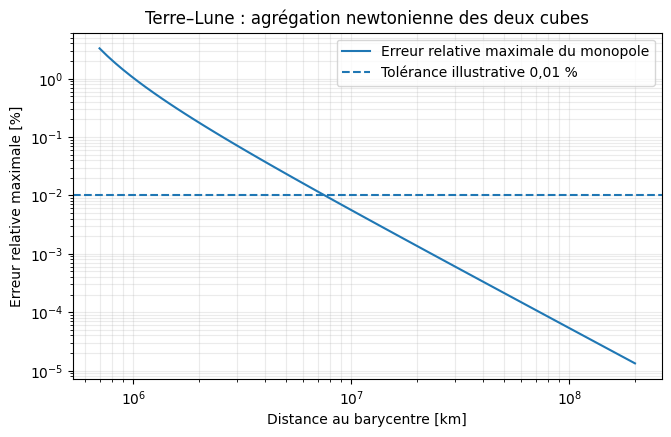

In [6]:
import matplotlib.pyplot as plt
rgrid=np.geomspace(0.7e9,2e11,70)
errgrid=np.array([100*np.max(field_errors_at_distance(r,xE,xM)) for r in rgrid])
fig,ax=plt.subplots(figsize=(7.6,4.5))
ax.loglog(rgrid/1e3,errgrid,label='Erreur relative maximale du monopole')
ax.axhline(REL_TOL_PERCENT,linestyle='--',label='Tolérance illustrative 0,01 %')
ax.set_xlabel('Distance au barycentre [km]')
ax.set_ylabel('Erreur relative maximale [%]')
ax.set_title('Terre–Lune : agrégation newtonienne des deux cubes')
ax.grid(True,which='both',alpha=.25)
ax.legend()
plt.show()


# Niveau 4 — Verdict scientifique

**Résultats attendus du protocole minimal**

- La formule barycentrique est vérifiée numériquement : `PASS` (identité de physique classique).
- L'erreur du cube agrégé décroît fortement avec la distance : `PASS` (témoin de validité d'une approximation multipolaire/monopolaire, et non d'une loi GVH).
- La fréquence orbitale à deux corps reproduit approximativement la période lunaire, avec un écart fini du fait du modèle simplifié : **benchmark physique établie**.
- Les rapports césium / fréquence orbitale sont définis et invariants sous une transformation *commune* du temps : **pas une résonance**, **pas une égalité forcée**, **pas une prédiction GVH**.

**Verrous explicitement conservés** :

1. Aucune équation du mouvement GVH dérivée pour les sous-cubes et leurs couplages dans ce notebook.
2. Pas de mécanisme couplant une transition atomique du césium à une fréquence orbitale.
3. Aucune échelle SI autonome dérivée du modèle GVH.
4. Les résultats ne prouvent aucune unification micro–macro, aucune fréquence universelle et aucune nouvelle physique.

**Prochaine question scientifique** : peut-on dériver d'une action GVH un couplage/une correction au modèle effectif que le benchmark newtonien ne prédit pas, avec au moins un observable tenu hors calibration ?


In [7]:
verdict={
    'notebook':'GVH_Hierarchical_Cube_Frequency_Minimal_Benchmark',
    'architecture':{
        'level_1_GVH':'HIERARCHICAL_CUBE_PROPOSAL_NOT_EOM_DERIVED',
        'level_2_established_physics':'NEWTONIAN_BARYCENTER_AND_NIST_FREQUENCY_BENCHMARK',
        'level_3_numeric':'BARYCENTER_AND_MONOPOLE_AND_FREQUENCY_WITNESS_PASS',
        'level_4_scientific_verdict':'BENCHMARK_CONSISTENT_NO_NEW_GVH_PHYSICS_VALIDATED',
    },
    'numerical':{
        'barycenter_identity_pass':BARYCENTER_IDENTITY_PASS,
        'error_falls_with_distance':FIELD_ERROR_FALLS_WITH_DISTANCE,
        'field_errors':field_df.to_dict(orient='records'),
        'P_moon_newton_days':p_moon_newton_d,
        'P_moon_reference_days':P_MOON_OBS_D,
        'P_moon_gap_percent_signed':rel_period_gap,
        'f_moon_observed_Hz':f_moon_observed,
        'f_earth_observed_Hz':f_earth_observed,
        'f_cs_reference_Hz':F_CS,
        'ratio_cs_moon':ratio_cs_moon,
        'ratio_cs_earth':ratio_cs_earth,
        'time_rescaling_invariant':COMMON_TIME_RESCALING_INVARIANCE_PASS,
    },
    'locks':{
        'GVH_EOM_DERIVED':False,
        'GVH_INDEPENDENT_SI_SCALE_DERIVED':False,
        'GVH_MICRO_MACRO_COUPLING_DERIVED':False,
        'GVH_INDEPENDENT_PREDICTION':False,
        'NEW_GVH_PHYSICS_VALIDATED':False,
    },
}
LOCAL_BENCHMARK_AUDIT_PASS = all([
    BARYCENTER_IDENTITY_PASS,
    FIELD_ERROR_FALLS_WITH_DISTANCE,
    TOL_PASS_AT_1E10,
    TOL_FAIL_AT_1E9,
    COMMON_TIME_RESCALING_INVARIANCE_PASS,
    not verdict['locks']['NEW_GVH_PHYSICS_VALIDATED'],
])
assert LOCAL_BENCHMARK_AUDIT_PASS
print('LOCAL_BENCHMARK_AUDIT_PASS =',LOCAL_BENCHMARK_AUDIT_PASS)
print('NEW_GVH_PHYSICS_VALIDATED =', verdict['locks']['NEW_GVH_PHYSICS_VALIDATED'])
print('LEVEL_4_VERDICT =',verdict['architecture']['level_4_scientific_verdict'])

# Export local de résultats (ne change pas les notebooks amont)
output_json=Path('/mnt/data/GVH_Hierarchical_Cube_Frequency_Minimal_Benchmark_results.json')
output_json.write_text(json.dumps(verdict,ensure_ascii=False,indent=2),encoding='utf-8')
print('Results JSON =',str(output_json))


LOCAL_BENCHMARK_AUDIT_PASS = True
NEW_GVH_PHYSICS_VALIDATED = False
LEVEL_4_VERDICT = BENCHMARK_CONSISTENT_NO_NEW_GVH_PHYSICS_VALIDATED
Results JSON = /mnt/data/GVH_Hierarchical_Cube_Frequency_Minimal_Benchmark_results.json
